In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from scipy.stats import wilcoxon

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
corr_df_dw = pd.read_csv(
    ".././6.2.2_corr_df_dw.csv",
    index_col=0,
)
binary_df_dw = pd.read_csv(
    ".././6.2.2_binary_df_dw.csv",
    index_col=0,
)

corr_df_full = pd.read_csv(
    ".././6.2_corr_df_full.csv",
    index_col=0,
)
binary_df_full = pd.read_csv(
    ".././6.2_binary_df_full.csv",
    index_col=0,
)

In [4]:
corr_df_dw.sample(2)

,analysis,method_1,method_2,n_cells,pearson_r,pearson_p,spearman_rho,spearman_p,GSM_id,Tissue_global,cell_type,method_pair,group
2698,primary,ds,sid,728,-0.032668,0.378777,-0.024170,0.514963,GSM7244920,Skin,Pericytes,ds – sid,Skin | Pericytes
239,primary,sp,ds,153,-0.109742,0.176893,-0.120661,0.137361,GSM5133598,Lung,Multiciliated epithelial cells,sp – ds,Lung | Multiciliated epithelial cells


In [5]:
binary_df_dw.sample(2)

,method_1,method_2,GSM_id,Tissue_global,cell_type,n_cells,n_Sc_m1,n_Sc_m2,TP,FP,FN,TN,sc_fraction_m1,sc_fraction_m2,jaccard,overlap_m1_given_m2,overlap_m2_given_m1,agreement,cohen_kappa,is_primary,method_pair,group
266,sp,ds,GSM5133603,Lung,T1 pneumocytes,545,11,67,2,9,65,469,0.020183,0.122936,0.026316,0.029851,0.181818,0.864220,0.017204,True,sp – ds,Lung | T1 pneumocytes
323,sp,ds,GSM5364336,Skin,Fibroblasts,622,77,43,2,75,41,504,0.123794,0.069132,0.016949,0.046512,0.025974,0.813505,-0.060778,True,sp – ds,Skin | Fibroblasts


In [9]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata, norm
from statsmodels.stats.multitest import multipletests


# Метрики и соответствующие датафреймы
metric_sources = {
    "Spearman rho": (corr_df_full, corr_df_dw, "spearman_rho"),
    "Cohen's kappa": (binary_df_full, binary_df_dw, "cohen_kappa"),
    "Jaccard index": (binary_df_full, binary_df_dw, "jaccard"),
}

group_cols = ["Tissue_global", "cell_type"]

method_pairs = {
    "ds – sid": ("ds", "sid"),
    "ds – sp": ("ds", "sp"),
    "sid – sp": ("sid", "sp"),
}


def paired_wilcoxon_effect(full_values, dw_values):
    """
    Парный двусторонний тест Вилкоксона и rank-biserial correlation.

    Разность = Downsampled - Full.
    Положительный RBC означает преобладание положительных рангов.
    """
    full_values = np.asarray(full_values, dtype=float)
    dw_values = np.asarray(dw_values, dtype=float)

    valid = np.isfinite(full_values) & np.isfinite(dw_values)
    differences = dw_values[valid] - full_values[valid]

    # Исключаем нулевые разности
    differences = differences[differences != 0]
    n = len(differences)

    if n == 0:
        return {
            "wilcoxon_statistic": 0.0,
            "p_value": 1.0,
            "effect_r": 0.0,
            "n_nonzero_diffs": 0,
        }

    test = wilcoxon(
        differences,
        alternative="two-sided",
        zero_method="wilcox",
        correction=False,
        method="auto",
    )

    # Суммы рангов положительных и отрицательных разностей
    ranks = rankdata(np.abs(differences), method="average")

    w_plus = ranks[differences > 0].sum()
    w_minus = ranks[differences < 0].sum()

    # Rank-biserial correlation
    effect_r = (w_plus - w_minus) / (w_plus + w_minus)

    return {
        "wilcoxon_statistic": test.statistic,
        "p_value": test.pvalue,
        "effect_r": effect_r,
        "n_nonzero_diffs": n,
    }


results = []

for metric, (df_full, df_dw, value_col) in metric_sources.items():
    for pair_name, (method_1, method_2) in method_pairs.items():
        # Выбираем нужную пару методов, учитывая оба возможных порядка
        def select_pair(df):
            direct = (df["method_1"] == method_1) & (df["method_2"] == method_2)
            reverse = (df["method_1"] == method_2) & (df["method_2"] == method_1)
            return df.loc[direct | reverse, group_cols + [value_col]].copy()

        full = select_pair(df_full)
        dw = select_pair(df_dw)

        # Одна строка на группу Tissue_global × cell_type
        full = (
            full.groupby(group_cols, as_index=False)[value_col]
            .mean()
            .rename(columns={value_col: "Full"})
        )
        dw = (
            dw.groupby(group_cols, as_index=False)[value_col]
            .mean()
            .rename(columns={value_col: "Downsampled"})
        )

        # Только общие группы с валидными значениями
        paired = full.merge(dw, on=group_cols, how="inner")
        paired = paired.dropna(subset=["Full", "Downsampled"])

        n_groups = len(paired)

        if n_groups == 0:
            test_results = {
                "wilcoxon_statistic": np.nan,
                "p_value": np.nan,
                "effect_r": np.nan,
                "n_nonzero_diffs": 0,
            }
            median_full = np.nan
            median_dw = np.nan
            median_diff = np.nan
        else:
            test_results = paired_wilcoxon_effect(
                paired["Full"].to_numpy(),
                paired["Downsampled"].to_numpy(),
            )

            median_full = paired["Full"].median()
            median_dw = paired["Downsampled"].median()
            median_diff = (paired["Downsampled"] - paired["Full"]).median()

        results.append(
            {
                "metric": metric,
                "method_pair": pair_name,
                "n_groups": n_groups,
                "n_nonzero_diffs": test_results["n_nonzero_diffs"],
                "median_full": median_full,
                "median_downsampled": median_dw,
                "median_difference": median_diff,
                "wilcoxon_statistic": test_results["wilcoxon_statistic"],
                "p_value": test_results["p_value"],
                "effect_r": test_results["effect_r"],
            }
        )


results_df = pd.DataFrame(results)

# FDR: отдельно для каждой метрики, по трём парам методов
results_df["FDR"] = np.nan

for metric in results_df["metric"].unique():
    mask = (results_df["metric"] == metric) & results_df["p_value"].notna()

    if mask.any():
        results_df.loc[mask, "FDR"] = multipletests(
            results_df.loc[mask, "p_value"],
            method="fdr_bh",
        )[1]

results_df = (
    results_df[
        [
            "metric",
            "method_pair",
            "n_groups",
            "n_nonzero_diffs",
            "median_full",
            "median_downsampled",
            "median_difference",
            "wilcoxon_statistic",
            "p_value",
            "FDR",
            "effect_r",
        ]
    ]
    .sort_values(["metric", "method_pair"])
    .reset_index(drop=True)
)

results_df

,metric,method_pair,n_groups,n_nonzero_diffs,median_full,median_downsampled,median_difference,wilcoxon_statistic,p_value,FDR,effect_r
0,Cohen's kappa,ds – sid,69,69,0.004061,0.004790,-0.002314,1058.0,0.371401,0.371401,-0.123810
1,Cohen's kappa,ds – sp,43,43,0.000050,0.009810,0.006952,373.0,0.232145,0.348218,0.211416
2,Cohen's kappa,sid – sp,45,45,-0.002270,0.007060,0.006306,320.0,0.025165,0.075495,0.381643
3,Jaccard index,ds – sid,69,69,0.066221,0.065515,-0.000199,1179.0,0.864696,0.864696,-0.023602
4,Jaccard index,ds – sp,43,43,0.062766,0.064172,0.001376,444.0,0.733333,0.864696,0.061311
5,Jaccard index,sid – sp,45,45,0.070818,0.077713,0.001427,432.0,0.340713,0.864696,0.165217
6,Spearman rho,ds – sid,69,69,0.016951,0.002803,-0.006856,853.0,0.034045,0.051068,-0.293582
7,Spearman rho,ds – sp,43,43,0.011436,0.050204,0.056771,291.0,0.027373,0.051068,0.384778
8,Spearman rho,sid – sp,45,45,-0.004311,0.006388,0.010699,467.0,0.575926,0.575926,0.097585


/tmp/ipykernel_161002/642964005.py:289: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.02, 0.08, 0.98, 0.93])


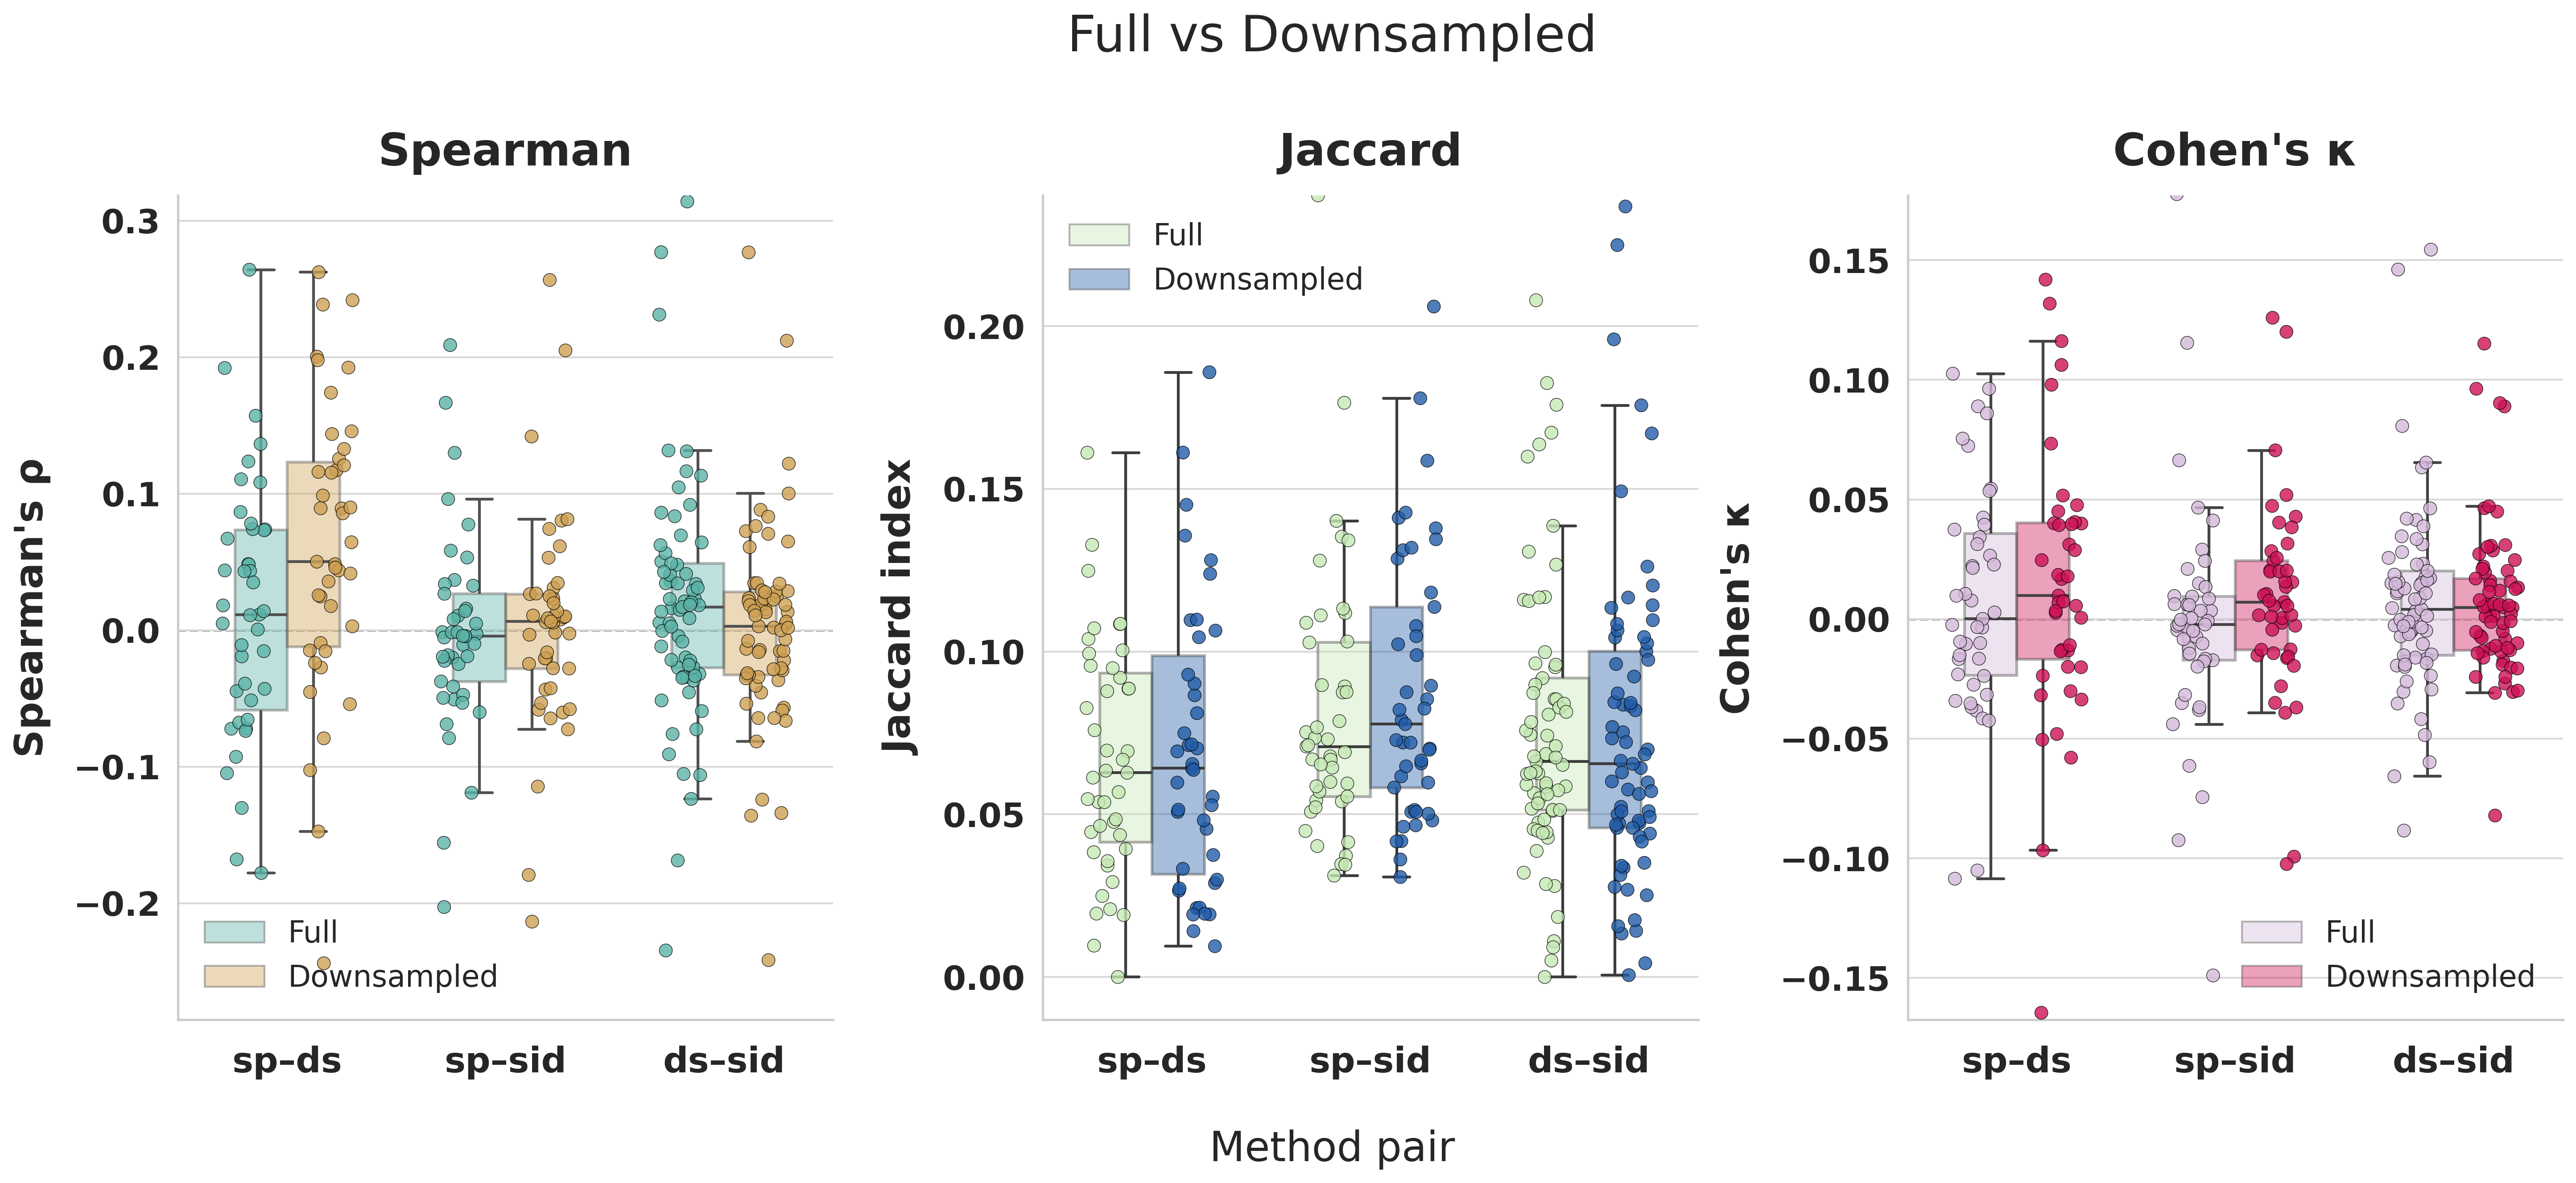

In [17]:
from matplotlib import colormaps
from matplotlib.patches import Patch


# ============================================================
# 1. Настройки
# ============================================================

sns.set_theme(style="whitegrid")

group_cols = ["Tissue_global", "cell_type"]

method_pairs = [
    ("sp", "ds"),
    ("sp", "sid"),
    ("ds", "sid"),
]

pair_labels = ["sp–ds", "sp–sid", "ds–sid"]

metrics = {
    "Spearman": {
        "full_df": corr_df_full,
        "dw_df": corr_df_dw,
        "column": "spearman_rho",
        "label": "Spearman's ρ",
        "cmap": "BrBG_r",
    },
    "Jaccard": {
        "full_df": binary_df_full,
        "dw_df": binary_df_dw,
        "column": "jaccard",
        "label": "Jaccard index",
        "cmap": "YlGnBu",
    },
    "Cohen's κ": {
        "full_df": binary_df_full,
        "dw_df": binary_df_dw,
        "column": "cohen_kappa",
        "label": "Cohen's κ",
        "cmap": "PuRd",
    },
}

metric_order = ["Spearman", "Jaccard", "Cohen's κ"]
dataset_order = ["Full", "Downsampled"]

# Цвета: 25% и 75% соответствующих палитр
palette = {}

for metric_name, settings in metrics.items():
    cmap = colormaps[settings["cmap"]]
    palette[metric_name] = {
        "Full": cmap(0.25),
        "Downsampled": cmap(0.75),
    }


# ============================================================
# 2. Подготовка данных
# ============================================================

plot_data = []

for metric_name in metric_order:
    settings = metrics[metric_name]
    value_col = settings["column"]

    for method_1, method_2 in method_pairs:
        pair_label = f"{method_1}–{method_2}"

        def select_pair(df):
            mask = ((df["method_1"] == method_1) & (df["method_2"] == method_2)) | (
                (df["method_1"] == method_2) & (df["method_2"] == method_1)
            )

            if "analysis" in df.columns:
                mask &= df["analysis"].eq("primary")

            return df.loc[mask, group_cols + [value_col]].copy()

        full = select_pair(settings["full_df"])
        dw = select_pair(settings["dw_df"])

        full = (
            full.groupby(group_cols, as_index=False)[value_col]
            .mean()
            .rename(columns={value_col: "Value"})
        )

        dw = (
            dw.groupby(group_cols, as_index=False)[value_col]
            .mean()
            .rename(columns={value_col: "Value"})
        )

        common = full.merge(
            dw,
            on=group_cols,
            how="inner",
            suffixes=("_full", "_dw"),
        )

        for dataset, suffix in [
            ("Full", "_full"),
            ("Downsampled", "_dw"),
        ]:
            values = common[f"Value{suffix}"].dropna()

            for value in values:
                plot_data.append(
                    {
                        "metric": metric_name,
                        "method_pair": pair_label,
                        "dataset": dataset,
                        "value": value,
                    }
                )

plot_df = pd.DataFrame(plot_data)

plot_df["metric"] = pd.Categorical(
    plot_df["metric"],
    categories=metric_order,
    ordered=True,
)

plot_df["method_pair"] = pd.Categorical(
    plot_df["method_pair"],
    categories=pair_labels,
    ordered=True,
)

plot_df["dataset"] = pd.Categorical(
    plot_df["dataset"],
    categories=dataset_order,
    ordered=True,
)


# ============================================================
# 3. Построение фигуры
# ============================================================

fig, axes = plt.subplots(
    ncols=3,
    nrows=1,
    figsize=(23, 8),
    dpi=300,
    gridspec_kw={"wspace": 0.32},
)

for ax, metric_name in zip(axes, metric_order):
    data = plot_df.loc[plot_df["metric"] == metric_name].copy()

    colors = palette[metric_name]

    # Боксы: медиана, IQR и усы 1.5 × IQR
    sns.boxplot(
        data=data,
        x="method_pair",
        y="value",
        hue="dataset",
        order=pair_labels,
        hue_order=dataset_order,
        palette=colors,
        width=0.48,
        dodge=True,
        whis=1.5,
        showfliers=False,
        linewidth=1.5,
        saturation=1,
        boxprops={"alpha": 0.4},
        ax=ax,
    )

    # Точки: повышенная контрастность
    sns.stripplot(
        data=data,
        x="method_pair",
        y="value",
        hue="dataset",
        order=pair_labels,
        hue_order=dataset_order,
        palette=colors,
        dodge=True,
        jitter=0.2,
        size=7,
        alpha=0.8,
        linewidth=0.35,
        edgecolor="black",
        legend=False,
        ax=ax,
        zorder=3,
    )

    # Нулевая линия для метрик, которые могут быть отрицательными
    if metric_name in ["Spearman", "Cohen's κ"]:
        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1.2,
            alpha=0.5,
            zorder=0,
        )

    # Заголовок панели
    ax.set_title(
        metric_name,
        fontsize=24,
        fontweight="semibold",
        pad=16,
    )

    ax.set_xlabel("")
    ax.set_ylabel(
        metrics[metric_name]["label"],
        fontsize=21,
        fontweight="semibold",
        labelpad=12,
    )

    ax.tick_params(axis="x", labelsize=19, pad=8)
    ax.tick_params(axis="y", labelsize=18)

    for label in ax.get_xticklabels():
        label.set_fontweight("semibold")

    for label in ax.get_yticklabels():
        label.set_fontweight("semibold")

    # Убираем рамки и вертикальную сетку
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(axis="y", color="0.85", linewidth=1.0)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

    # Ограничения оси Y по 1-му и 99-му перцентилям
    values = data["value"].dropna()

    if len(values) > 0:
        y_min, y_max = np.percentile(values, [1, 99])
        y_range = y_max - y_min

        padding = max(y_range * 0.08, 0.01)
        ax.set_ylim(y_min - padding, y_max + padding)

    # Отдельная легенда для каждой панели со своими цветами
    legend_handles = [
        Patch(
            facecolor=colors[dataset],
            edgecolor="0.3",
            linewidth=1.0,
            alpha=0.4,
            label=dataset,
        )
        for dataset in dataset_order
    ]

    ax.legend(
        handles=legend_handles,
        title="",
        loc="best",
        frameon=False,
        fontsize=16,
        title_fontsize=17,
    )


# ============================================================
# 4. Общая подпись оси X и заголовок
# ============================================================

fig.supxlabel(
    "Method pair",
    fontsize=22,
    # fontweight="semibold",
    y=-0.03,
)

fig.suptitle(
    "Full vs Downsampled",
    fontsize=27,
    # fontweight="semibold",
    y=1.05,
)

plt.tight_layout(rect=[0.02, 0.08, 0.98, 0.93])
plt.show()